# Course 10: AI Research in 2026
## Session 12: Seeing in 4D: feed-forward reconstruction, and what comes next

**Goal:** reconstruct moving objects from a toy video in two ways, per-scene optimization and one feed-forward network answering point queries, and compare their accuracy, speed and robustness.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### The 2026 paper
Zhang, Sajjadi and colleagues (Google DeepMind, UCL and Oxford), *Efficiently Reconstructing Dynamic Scenes One D4RT at a Time* (CVPR 2026 Best Paper). A single transformer reads one video and jointly estimates depth, correspondence over time and camera parameters. A global self-attention encoder builds a latent scene representation; a lightweight decoder answers independent **point queries**: where is the point seen at pixel $(u, v)$ of frame $t_{src}$ at time $t_{tgt}$, in the coordinates of camera $t_{cam}$? Depth maps, point tracks, point clouds and camera poses all come from the same query interface.

This lab is a toy illustration, not a reproduction. Our world is 2-D, with two moving discs seen by a fixed 1-D pinhole camera for 6 frames. Because the camera does not move, our queries drop $t_{cam}$. Our encoder is a 2-layer transformer over 6 frame tokens, trained on synthetic scenes for about a minute; D4RT is far larger and trained on real and synthetic videos. The per-scene method below knows the true form of the world (two discs moving at constant speed), which a real per-scene method such as NeRF or Gaussian splatting does not.

### 1. A toy dynamic world and its video
Each scene has two discs of radius 0.5 (one red, one blue) moving at constant velocity in front of a pinhole camera at the origin looking along $+y$. Pixel $u$ sees along the ray through $(u, 1)$; each of the 48 pixels records which disc it hits first (occlusion is handled), or nothing. A frame is therefore a 1-D colour image, and the video is 6 such frames. Depth is not measured; it can only be inferred, for example from how wide a disc looks.

In [1]:
import math
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.set_num_threads(2)
np.random.seed(0)
torch.manual_seed(0)
T, W, K, R = 6, 48, 2, 0.5                                # frames, pixels, discs, disc radius
U = torch.linspace(-0.6, 0.6, W)                          # pixel coordinates u = x / y
DIRS = torch.stack([U, torch.ones(W)], -1)
DIRS = DIRS / DIRS.norm(dim=-1, keepdim=True)             # unit ray direction of each pixel

def make_scenes(n, gen, vmax=0.3):
    c0 = torch.stack([torch.rand(n, K, generator=gen) * 3 - 1.5,          # x in [-1.5, 1.5]
                      torch.rand(n, K, generator=gen) * 3 + 3.5], -1)     # y (depth) in [3.5, 6.5]
    v = (torch.rand(n, K, 2, generator=gen) * 2 - 1) * vmax              # velocity per frame
    return c0, v

def centers(c0, v):                                                       # (n, T, K, 2)
    return c0[:, None] + v[:, None] * torch.arange(T).float()[None, :, None, None]

def render(c0, v):
    C = centers(c0, v)
    proj = C @ DIRS.T                                                     # distance along each ray to the closest approach
    perp2 = (C ** 2).sum(-1)[..., None] - proj ** 2                       # squared distance from centre to the ray
    hit = perp2 < R ** 2
    t_hit = torch.where(hit, proj - torch.sqrt(torch.clamp(R ** 2 - perp2, min=0)), torch.full_like(proj, 1e9))
    first = t_hit.argmin(2)                                               # which disc is hit first
    video = F.one_hot(first, K).permute(0, 1, 3, 2).float() * hit.any(2)[:, :, None, :].float()
    return video, t_hit                                                   # video (n, T, K, W)

gen = torch.Generator().manual_seed(7)
c0_demo, v_demo = make_scenes(1, gen)
video_demo, _ = render(c0_demo, v_demo)
fmt = lambda a: "[" + ", ".join("(" + ", ".join(f"{x:.3f}" for x in row) + ")" for row in a.tolist()) + "]"
print(f"one scene: disc centres at t = 0: {fmt(c0_demo[0])}, velocities per frame: {fmt(v_demo[0])}")
print(f"pixels covered per frame (red, blue): {video_demo[0].sum(-1).int().tolist()}")

one scene: disc centres at t = 0: [(0.105, 5.478), (-0.904, 5.471)], velocities per frame: [(-0.160, -0.045), (-0.176, 0.078)]
pixels covered per frame (red, blue): [[7, 7], [7, 7], [7, 7], [7, 7], [8, 6], [8, 7]]


### 2. Point queries
A query $(u, t_{src}, t_{tgt})$ asks: the surface point seen at pixel $u$ in frame $t_{src}$, where is it at time $t_{tgt}$? With $t_{tgt} = t_{src}$ for every pixel we get a depth map (a point cloud of the frame); with fixed $u, t_{src}$ and all $t_{tgt}$ we get a track. The answer comes from geometry: intersect the pixel's ray with the disc it sees, then move that point with the disc's velocity.

In [2]:
def make_queries(c0, v, n_q, gen):
    video, t_hit = render(c0, v)
    n = len(c0)
    seen = video.sum(2) > 0                                               # (n, T, W): pixel sees a disc
    t_src = torch.multinomial(seen.any(-1).float() + 1e-9, n_q, replacement=True, generator=gen)
    t_tgt = torch.randint(0, T, (n, n_q), generator=gen)
    rows = torch.arange(n)[:, None]
    pix = torch.multinomial(seen[rows, t_src].float().view(-1, W) + 1e-9, 1, generator=gen).view(n, n_q)
    valid = seen[rows, t_src, pix]                                        # False only if a whole scene is out of view
    k = video[rows, t_src, :, pix].argmax(-1)
    depth = torch.where(valid, t_hit[rows, t_src, k, pix], torch.zeros(()))
    target = depth[..., None] * DIRS[pix] + v[rows, k] * (t_tgt - t_src)[..., None].float()
    queries = torch.stack([U[pix], t_src.float() / (T - 1), t_tgt.float() / (T - 1)], -1)
    return video, queries, target, valid

q_video, q_demo, tgt_demo, ok_demo = make_queries(c0_demo, v_demo, 4, torch.Generator().manual_seed(1))
for q, t in zip(q_demo[0], tgt_demo[0]):
    print(f"query u = {q[0]:+.3f}, t_src = {round(q[1].item() * 5)}, t_tgt = {round(q[2].item() * 5)}  ->  position {t.numpy().round(3)}")

query u = -0.115, t_src = 0, t_tgt = 5  ->  position [-1.463  5.475]
query u = +0.064, t_src = 1, t_tgt = 0  ->  position [0.486 5.155]
query u = +0.013, t_src = 1, t_tgt = 2  ->  position [-0.097  4.902]
query u = -0.115, t_src = 1, t_tgt = 3  ->  position [-0.967  5.516]


### 3. The feed-forward model: encode once, then answer queries
The encoder turns each frame into a token, adds a time embedding and runs 2 layers of self-attention across the 6 frames: this is the latent scene representation. The decoder embeds a query, attends to the latent tokens with cross-attention, and outputs a 2-D position. Every query is answered independently, so a scene is encoded once and then queried as often as needed. We train it on fresh random scenes with ground-truth answers, minimizing the mean distance between predicted and true positions.

In [3]:
class QueryReconstructor(nn.Module):
    def __init__(self, d=64):
        super().__init__()
        self.frame = nn.Linear(K * W, d)
        self.time = nn.Parameter(torch.randn(T, d) * 0.02)
        self.encoder = nn.TransformerEncoder(nn.TransformerEncoderLayer(d, 4, 4 * d, dropout=0.0, batch_first=True), 2)
        self.freqs = torch.arange(1, 9).float() * math.pi
        self.query = nn.Sequential(nn.Linear(3 + 16, d), nn.GELU(), nn.Linear(d, d))
        self.cross = nn.MultiheadAttention(d, 4, batch_first=True)
        self.out = nn.Sequential(nn.Linear(2 * d, d), nn.GELU(), nn.Linear(d, 2))

    def encode(self, video):                              # (n, T, K, W) -> latent tokens (n, T, d)
        return self.encoder(self.frame(video.flatten(2)) + self.time)

    def decode(self, latent, queries):                    # (n, Q, 3) -> positions (n, Q, 2)
        u = queries[..., :1]
        h = self.query(torch.cat([queries, torch.sin(u * self.freqs), torch.cos(u * self.freqs)], -1))
        a, _ = self.cross(h, latent, latent)
        return self.out(torch.cat([h, a], -1)) + torch.tensor([0.0, 5.0])

torch.manual_seed(0)
model = QueryReconstructor()
STEPS = 1200
opt = torch.optim.AdamW(model.parameters(), lr=2e-3)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=STEPS)
gen = torch.Generator().manual_seed(0)
t0 = time.time()
for step in range(STEPS):
    c0, v = make_scenes(64, gen)
    video, queries, target, valid = make_queries(c0, v, 32, gen)
    err = (model.decode(model.encode(video), queries) - target).norm(dim=-1)
    loss = err[valid].mean()
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    if step % 300 == 0 or step == STEPS - 1:
        print(f"step {step:4d}   mean position error on the training batch {loss.item():.3f}")
train_seconds = time.time() - t0
print(f"training took {train_seconds:.0f} s for {STEPS * 64:,} random scenes (a one-off cost)")

step    0   mean position error on the training batch 1.408


step  300   mean position error on the training batch 0.592


step  600   mean position error on the training batch 0.475


step  900   mean position error on the training batch 0.310


step 1199   mean position error on the training batch 0.315
training took 32 s for 76,800 random scenes (a one-off cost)


### 4. Per-scene optimization: fit each scene on its own
The classical alternative fits a separate small model to each video, like NeRF or Gaussian splatting do for each scene (Course 9, session 11). Our model is an explicit field: two soft discs, each with a start position and a velocity (8 numbers per scene). We initialize it from simple measurements (each disc's width in a frame gives its depth, its middle gives its direction, and a straight line through the frames gives the velocity), then refine it by gradient descent on a differentiable renderer, comparing rendered and observed frames. A soft edge that sharpens over 300 steps makes the gradients useful. All scenes are fitted at once in one tensor, but each scene's numbers are optimized independently.

In [4]:
def soft_render(c0, v, tau):                              # differentiable version of render(), with soft edges and soft occlusion
    C = centers(c0, v)
    proj = C @ DIRS.T
    perp = torch.sqrt(torch.clamp((C ** 2).sum(-1)[..., None] - proj ** 2, min=1e-9))
    alpha = torch.sigmoid((R - perp) / tau)               # soft coverage of each pixel by each disc
    other_in_front = torch.sigmoid((proj - proj[:, :, [1, 0]]) / 0.05)
    return alpha * (1 - alpha[:, :, [1, 0]] * other_in_front)

def init_from_frames(video):                              # video (T, K, W) -> c0, v for one scene
    c0, v = torch.zeros(K, 2), torch.zeros(K, 2)
    step_u = (U[1] - U[0]).item()
    for k in range(K):
        ts, xs, ys = [], [], []
        for t in range(T):
            on = torch.nonzero(video[t, k]).flatten()
            if len(on) < 2:
                continue
            lo, hi = on.min().item(), on.max().item()
            if lo == 0 or hi == W - 1 or (video[t, 1 - k, max(lo - 1, 0)] > 0) or (video[t, 1 - k, min(hi + 1, W - 1)] > 0):
                continue                                  # cut by the image edge or touching the other disc
            u_left, u_right = U[lo].item() - step_u / 2, U[hi].item() + step_u / 2
            y = 2 * R / (u_right - u_left)
            ts.append(t); xs.append(0.5 * (u_left + u_right) * y); ys.append(y)
        if len(ts) >= 2:
            A = np.stack([np.ones(len(ts)), np.array(ts)], 1)
            (x0, vx), (y0, vy) = np.linalg.lstsq(A, np.array(xs), rcond=None)[0], np.linalg.lstsq(A, np.array(ys), rcond=None)[0]
            c0[k], v[k] = torch.tensor([x0, y0]), torch.tensor([vx, vy])
        elif len(ts) == 1:
            c0[k] = torch.tensor([xs[0], ys[0]])
        else:
            c0[k] = torch.tensor([0.0, 5.0])
    return c0, v

def fit_scenes(video, steps=300):
    inits = [init_from_frames(vid) for vid in video]
    c0 = torch.stack([a for a, _ in inits]).requires_grad_(True)
    v = torch.stack([b for _, b in inits]).requires_grad_(True)
    opt = torch.optim.Adam([c0, v], lr=0.02)
    for s in range(steps):
        tau = 0.2 * 0.1 ** (s / steps)                    # soft edges first, sharp edges at the end
        loss = ((soft_render(c0, v, tau) - video) ** 2).mean(dim=(1, 2, 3)).sum()
        opt.zero_grad(); loss.backward(); opt.step()
    return c0.detach(), v.detach()

def answer_from_fit(c0, v, queries, video):               # use the observed colour at the pixel to pick the disc
    n, Q, _ = queries.shape
    rows = torch.arange(n)[:, None]
    u = queries[..., 0]
    t_src = torch.round(queries[..., 1] * (T - 1)).long()
    t_tgt = torch.round(queries[..., 2] * (T - 1)).long()
    pix = torch.round((u + 0.6) / 1.2 * (W - 1)).long()
    k = video[rows, t_src, :, pix].argmax(-1)
    d = DIRS[pix]
    C = c0[rows, k] + v[rows, k] * t_src[..., None].float()
    proj = (C * d).sum(-1)
    perp2 = (C ** 2).sum(-1) - proj ** 2
    depth = torch.where(perp2 < R ** 2, proj - torch.sqrt(torch.clamp(R ** 2 - perp2, min=0)), proj)
    return depth[..., None] * d + v[rows, k] * (t_tgt - t_src)[..., None].float()

c_hat, v_hat = fit_scenes(video_demo)
print(f"demo scene, fitted centres    {fmt(c_hat[0])}   true {fmt(c0_demo[0])}")
print(f"demo scene, fitted velocities {fmt(v_hat[0])}   true {fmt(v_demo[0])}")

demo scene, fitted centres    [(0.092, 5.408), (-0.838, 5.439)]   true [(0.105, 5.478), (-0.904, 5.471)]
demo scene, fitted velocities [(-0.148, -0.058), (-0.166, 0.022)]   true [(-0.160, -0.045), (-0.176, 0.078)]


### 5. Accuracy, speed and robustness
Two test sets of 40 new scenes with 64 queries each: scenes like the training scenes (speeds up to 0.3 per frame), and faster scenes (up to 0.6) that the feed-forward model never saw. We report the median query error, the 90th percentile, the share of queries answered within 0.2, and the wall-clock time per scene on this CPU.

like training (speed <= 0.3)
  feed-forward:      median 0.183   90th pct 0.500   within 0.2: 0.54      0.15 ms per scene
  per-scene fit:     median 0.101   90th pct 0.319   within 0.2: 0.78     15.33 ms per scene (300 renderer steps each)


faster (speed <= 0.6)
  feed-forward:      median 0.347   90th pct 1.183   within 0.2: 0.29      0.12 ms per scene
  per-scene fit:     median 0.093   90th pct 0.340   within 0.2: 0.77     14.79 ms per scene (300 renderer steps each)
(the feed-forward model also needed 32 s of training once)


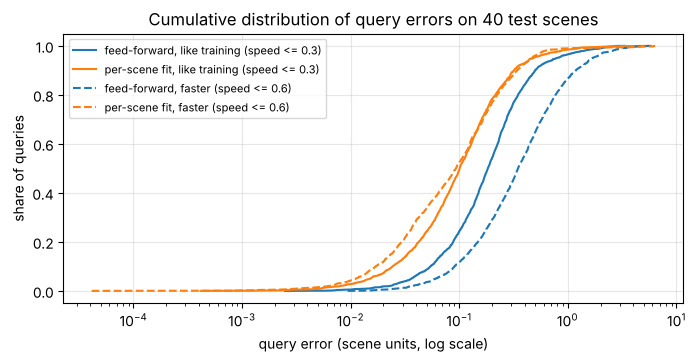

In [5]:
def summary(err):
    return f"median {err.median():.3f}   90th pct {err.quantile(0.9):.3f}   within 0.2: {(err < 0.2).float().mean():.2f}"

results = {}
for name, vmax in [("like training (speed <= 0.3)", 0.3), ("faster (speed <= 0.6)", 0.6)]:
    gen = torch.Generator().manual_seed(123)
    c0, v = make_scenes(40, gen, vmax)
    video, queries, target, valid = make_queries(c0, v, 64, gen)
    t0 = time.time()
    with torch.no_grad():
        pred_ff = model.decode(model.encode(video), queries)
    ms_ff = (time.time() - t0) / 40 * 1000
    t0 = time.time()
    c_fit, v_fit = fit_scenes(video)
    pred_ps = answer_from_fit(c_fit, v_fit, queries, video)
    ms_ps = (time.time() - t0) / 40 * 1000
    e_ff = (pred_ff - target).norm(dim=-1)[valid]
    e_ps = (pred_ps - target).norm(dim=-1)[valid]
    results[name] = (e_ff, e_ps)
    print(f"{name}\n  feed-forward:      {summary(e_ff)}   {ms_ff:7.2f} ms per scene"
          f"\n  per-scene fit:     {summary(e_ps)}   {ms_ps:7.2f} ms per scene (300 renderer steps each)")
print(f"(the feed-forward model also needed {train_seconds:.0f} s of training once)")

plt.figure(figsize=(8, 3.5))
for (name, (e_ff, e_ps)), ls in zip(results.items(), ["-", "--"]):
    for err, label, color in [(e_ff, "feed-forward", "C0"), (e_ps, "per-scene fit", "C1")]:
        xs = np.sort(err.numpy())
        plt.plot(xs, np.arange(1, len(xs) + 1) / len(xs), ls=ls, color=color, label=f"{label}, {name}")
plt.xscale("log"); plt.xlabel("query error (scene units, log scale)"); plt.ylabel("share of queries")
plt.title("Cumulative distribution of query errors on 40 test scenes")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

### 6. One scene, two answers: a track
Pick a pixel that sees the red disc in frame 0 and ask where that point is in every frame.

frame   true position     feed-forward      per-scene fit
    0   [-0.732  5.21 ]   [-0.704  5.313]   [-0.736  5.24 ]
    1   [-0.669  5.501]   [-0.814  5.392]   [-0.654  5.83 ]
    2   [-0.607  5.791]   [-1.001  5.434]   [-0.572  6.419]
    3   [-0.544  6.081]   [-1.258  5.427]   [-0.49   7.009]
    4   [-0.482  6.371]   [-1.496  5.396]   [-0.407  7.598]
    5   [-0.419  6.661]   [-1.662  5.386]   [-0.325  8.188]


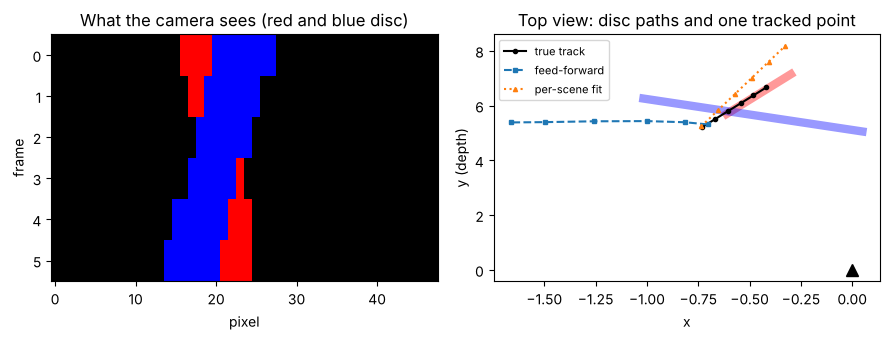

In [6]:
gen = torch.Generator().manual_seed(123)
c0, v = make_scenes(40, gen, 0.3)
video, _ = render(c0, v)
i = 0
pix = int(torch.nonzero(video[i, 0, 0]).flatten()[len(torch.nonzero(video[i, 0, 0])) // 2])
queries = torch.tensor([[[U[pix].item(), 0.0, t / (T - 1)] for t in range(T)]])
with torch.no_grad():
    track_ff = model.decode(model.encode(video[i:i + 1]), queries)[0]
c_fit, v_fit = fit_scenes(video[i:i + 1])
track_ps = answer_from_fit(c_fit, v_fit, queries, video[i:i + 1])[0]
_, t_hit = render(c0[i:i + 1], v[i:i + 1])
start = t_hit[0, 0, 0, pix] * DIRS[pix]
track_true = start + v[i, 0] * torch.arange(T).float()[:, None]
print("frame   true position     feed-forward      per-scene fit")
for t in range(T):
    print(f"{t:5d}   {track_true[t].numpy().round(3)}   {track_ff[t].numpy().round(3)}   {track_ps[t].numpy().round(3)}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.5))
rgb = np.zeros((T, W, 3)); rgb[..., 0] = video[i, :, 0].numpy(); rgb[..., 2] = video[i, :, 1].numpy()
ax1.imshow(rgb, aspect="auto", interpolation="nearest")
ax1.set_xlabel("pixel"); ax1.set_ylabel("frame"); ax1.set_title("What the camera sees (red and blue disc)")
for k, col in enumerate(["red", "blue"]):
    path = centers(c0[i:i + 1], v[i:i + 1])[0, :, k]
    ax2.plot(path[:, 0], path[:, 1], color=col, alpha=0.4, lw=6)
ax2.plot(track_true[:, 0], track_true[:, 1], "k-o", ms=3, label="true track")
ax2.plot(track_ff[:, 0], track_ff[:, 1], "C0--s", ms=3, label="feed-forward")
ax2.plot(track_ps[:, 0], track_ps[:, 1], "C1:^", ms=3, label="per-scene fit")
ax2.plot(0, 0, "k^", ms=8); ax2.set_xlabel("x"); ax2.set_ylabel("y (depth)")
ax2.set_title("Top view: disc paths and one tracked point"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 7. A real feed-forward reconstructor (NOT RUN here)
VGGT (CVPR 2025 Best Paper) predicts cameras, depth maps and point maps from a set of images in one forward pass. Its public code runs like this; try it on frames you extract from a short phone video.

In [ ]:
# NOT RUN: needs a GPU and downloads (the VGGT code from github.com/facebookresearch/vggt and its pretrained weights)
import torch
from vggt.models.vggt import VGGT
from vggt.utils.load_fn import load_and_preprocess_images

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
model = VGGT.from_pretrained("facebook/VGGT-1B").to(device)
image_names = ["frame_000.png", "frame_010.png", "frame_020.png"]      # your own frames
images = load_and_preprocess_images(image_names).to(device)
with torch.no_grad():
    with torch.cuda.amp.autocast(dtype=dtype):
        predictions = model(images)
print(predictions.keys())

### TODO
1. Give the per-scene fit fewer steps (0, 30 and 100 instead of 300) and plot its median error against time per scene. Where does it pass the feed-forward model?
2. Test both methods on scenes with discs of radius 0.7. Which method breaks, and which assumption does each one rely on?

In [7]:
# TODO: per-scene fit with a step budget; return a list of (steps, median error, ms per scene)
def accuracy_vs_steps(step_list=(0, 30, 100, 300)):
    return None          # replace: call fit_scenes(video, steps=s) on the first test set and time it

out = accuracy_vs_steps()
print("not done yet" if out is None else out)

not done yet


### What to notice
- **One interface, many outputs.** The same query function gives depth (when $t_{tgt} = t_{src}$) and tracks (when $t_{tgt}$ varies), which is the idea behind D4RT's decoder.
- **Feed-forward is fast at test time.** It answered all queries for a scene in well under a millisecond, while the per-scene fit took tens of milliseconds per scene even with 40 scenes fitted together in one tensor. The feed-forward model paid for this with about half a minute of training, once.
- **Per-scene fitting was more accurate here**, with a median error of 0.101 against 0.183 and 78% against 54% of queries within 0.2, on scenes like the training scenes. This is partly unfair to the network: the per-scene model knows the world has exactly two discs moving at constant speed, while the network had to learn everything from examples.
- **Generalization is the feed-forward model's weak point in this toy.** On faster scenes than it was trained on, its median error almost doubled (0.347) and only 29% of its answers were within 0.2, while the per-scene fit did not care (median 0.093, 77% within 0.2).
- **Occlusion and depth from one camera are hard for both.** In the plotted scene the red disc passes behind the blue one (it is completely hidden in frame 2). The feed-forward track drifts left, following the blue disc; the per-scene fit gets the direction right but overestimates how fast the disc moves away (depth 8.19 instead of 6.66 at frame 5). With one camera, depth comes only from apparent width, which here is quantized to whole pixels.
- None of this tests D4RT's claims. It shows the trade-off the paper's approach makes: amortized speed in exchange for dependence on the training distribution.